# Proyecto BI – Equipo 5: Recursos Humanos
## Notebook 2 de 2: Hipótesis, validación estadística, KPIs y storytelling
Usa `data/hr_attrition_clean.csv`, que se genera en `01_limpieza_eda.ipynb` (correr ese notebook primero).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='Set2')

df = pd.read_csv('../data/hr_attrition_clean.csv', encoding='utf-8-sig')
print(df.shape)

(1470, 50)


# Fase 2. Formulación de hipótesis
Nivel de significancia **α = 0,05** para todas las pruebas. Si p < α se rechaza H0.

| # | Hipótesis | Variables | Prueba |
|---|---|---|---|
| H1 | Las horas extra se asocian con la rotación | OverTime × Attrition | Chi-cuadrado de independencia + V de Cramér |
| H2 | Quienes se van ganan menos que quienes se quedan | MonthlyIncome × Attrition | Mann-Whitney U (tras probar normalidad) |
| H3 | La satisfacción laboral se asocia con la rotación | JobSatisfaction × Attrition | Chi-cuadrado + Mann-Whitney |
| H4 | La rotación difiere entre departamentos | Department × Attrition | Chi-cuadrado |
| H5 | Los empleados que se van tienen menos antigüedad | YearsAtCompany × Attrition | Mann-Whitney U |

**Por qué importan:** H1 y H5 se pueden atacar con política de carga laboral y onboarding; H2 con política salarial; H3 con clima organizacional; H4 sirve para priorizar áreas.

In [2]:
def chi2_test(var, nombre):
    tab = pd.crosstab(df[var], df.Attrition)
    chi2, p, dof, exp = stats.chi2_contingency(tab)
    n = tab.values.sum(); v = np.sqrt(chi2/(n*(min(tab.shape)-1)))
    print(f'--- {nombre} ---'); print(tab)
    print(f'Chi2={chi2:.2f}, gl={dof}, p={p:.2e}, V de Cramér={v:.3f}, esperados mín={exp.min():.1f}')
    print('Decisión:', 'Se RECHAZA H0' if p<0.05 else 'NO se rechaza H0'); print()
    return dict(Prueba='Chi-cuadrado', Estadistico=round(chi2,2), p_valor=p, Efecto=f'V={v:.3f}')

def mw_test(var, nombre):
    a, b = df.loc[df.Rotacion==1,var], df.loc[df.Rotacion==0,var]
    print(f'--- {nombre} ---')
    print(f'Shapiro (se fue) p={stats.shapiro(a).pvalue:.2e} | Shapiro (activo) p={stats.shapiro(b).pvalue:.2e}  -> no normal, se usa prueba no paramétrica')
    u, p = stats.mannwhitneyu(a, b, alternative='less')
    r = 1 - 2*u/(len(a)*len(b))  # correlación rank-biserial
    print(f'Mediana se fue={a.median():.1f} | activo={b.median():.1f}')
    print(f'U={u:.0f}, p (unilateral, se fue < activo)={p:.2e}, r rank-biserial={r:.3f}')
    print('Decisión:', 'Se RECHAZA H0' if p<0.05 else 'NO se rechaza H0'); print()
    return dict(Prueba='Mann-Whitney U', Estadistico=round(u,0), p_valor=p, Efecto=f'r={r:.3f}')

### H1 – Horas extra
- **H0:** Hacer horas extra y la rotación son independientes.
- **H1:** Hacer horas extra y la rotación están asociadas.

In [3]:
res = {}
res['H1 Horas extra'] = chi2_test('OverTime','H1: OverTime vs Attrition')
print((df.groupby('OverTime_Txt').Rotacion.mean()*100).round(1))

--- H1: OverTime vs Attrition ---
Attrition   No  Yes
OverTime           
No         944  110
Yes        289  127
Chi2=87.56, gl=1, p=8.16e-21, V de Cramér=0.244, esperados mín=67.1
Decisión: Se RECHAZA H0

OverTime_Txt
No    10.4
Sí    30.5
Name: Rotacion, dtype: float64


### H2 – Ingreso mensual
- **H0:** La distribución del ingreso de quienes se van es igual o mayor que la de quienes se quedan.
- **H1:** El ingreso de quienes se van es menor (prueba unilateral).

In [4]:
res['H2 Ingreso'] = mw_test('MonthlyIncome','H2: MonthlyIncome')

--- H2: MonthlyIncome ---
Shapiro (se fue) p=1.50e-17 | Shapiro (activo) p=5.97e-34  -> no normal, se usa prueba no paramétrica
Mediana se fue=3202.0 | activo=5204.0
U=100620, p (unilateral, se fue < activo)=1.48e-14, r rank-biserial=0.311
Decisión: Se RECHAZA H0



### H3 – Satisfacción laboral
- **H0:** La satisfacción laboral y la rotación son independientes.
- **H1:** Existe asociación (se espera más rotación cuando la satisfacción es baja).

In [5]:
res['H3 Satisfacción'] = chi2_test('JobSatisfaction_Txt','H3: JobSatisfaction vs Attrition')
print((df.groupby('JobSatisfaction_Txt').Rotacion.mean()*100).round(1))
mw_test('JobSatisfaction','H3 complementaria: JobSatisfaction (ordinal)')

--- H3: JobSatisfaction vs Attrition ---
Attrition             No  Yes
JobSatisfaction_Txt          
Alta                 369   73
Baja                 223   66
Media                234   46
Muy alta             407   52
Chi2=17.51, gl=3, p=5.56e-04, V de Cramér=0.109, esperados mín=45.1
Decisión: Se RECHAZA H0

JobSatisfaction_Txt
Alta        16.5
Baja        22.8
Media       16.4
Muy alta    11.3
Name: Rotacion, dtype: float64
--- H3 complementaria: JobSatisfaction (ordinal) ---
Shapiro (se fue) p=2.31e-14 | Shapiro (activo) p=2.88e-33  -> no normal, se usa prueba no paramétrica
Mediana se fue=3.0 | activo=3.0
U=123362, p (unilateral, se fue < activo)=3.98e-05, r rank-biserial=0.156
Decisión: Se RECHAZA H0



{'Prueba': 'Mann-Whitney U',
 'Estadistico': np.float64(123362.0),
 'p_valor': np.float64(3.978958920445506e-05),
 'Efecto': 'r=0.156'}

### H4 – Departamento
- **H0:** La rotación es igual en todos los departamentos.
- **H1:** Al menos un departamento tiene una tasa distinta.

In [6]:
res['H4 Departamento'] = chi2_test('Department_Txt','H4: Department vs Attrition')

--- H4: Department vs Attrition ---
Attrition        No  Yes
Department_Txt          
I+D             828  133
RR.HH.           51   12
Ventas          354   92
Chi2=10.80, gl=2, p=4.53e-03, V de Cramér=0.086, esperados mín=10.2
Decisión: Se RECHAZA H0



### H5 – Antigüedad
- **H0:** La antigüedad de quienes se van es igual o mayor que la de quienes se quedan.
- **H1:** Quienes se van tienen menos años en la empresa.

In [7]:
res['H5 Antigüedad'] = mw_test('YearsAtCompany','H5: YearsAtCompany')

--- H5: YearsAtCompany ---
Shapiro (se fue) p=1.30e-19 | Shapiro (activo) p=1.67e-32  -> no normal, se usa prueba no paramétrica
Mediana se fue=3.0 | activo=6.0
U=102582, p (unilateral, se fue < activo)=1.46e-13, r rank-biserial=0.298
Decisión: Se RECHAZA H0



### Resumen de pruebas

In [8]:
resumen = pd.DataFrame(res).T
resumen['Decisión (α=0.05)'] = np.where(resumen.p_valor<0.05,'Rechaza H0','No rechaza H0')
resumen['p_valor'] = resumen.p_valor.map(lambda x: f'{x:.2e}')
resumen

,Prueba,Estadistico,p_valor,Efecto,Decisión (α=0.05)
H1 Horas extra,Chi-cuadrado,87.56,8.16e-21,V=0.244,Rechaza H0
H2 Ingreso,Mann-Whitney U,100620.0,1.48e-14,r=0.311,Rechaza H0
H3 Satisfacción,Chi-cuadrado,17.51,5.56e-04,V=0.109,Rechaza H0
H4 Departamento,Chi-cuadrado,10.8,4.53e-03,V=0.086,Rechaza H0
H5 Antigüedad,Mann-Whitney U,102582.0,1.46e-13,r=0.298,Rechaza H0


### Validación multivariada (regresión logística)
Las pruebas anteriores miran una variable a la vez. Para comprobar que los efectos se mantienen cuando se controlan las demás variables, se ajusta un modelo logístico y se revisan los *odds ratios*.

AUC en prueba: 0.795
              precision    recall  f1-score   support

      Activo       0.93      0.78      0.85       309
      Se fue       0.38      0.69      0.49        59

    accuracy                           0.77       368
   macro avg       0.65      0.74      0.67       368
weighted avg       0.84      0.77      0.79       368



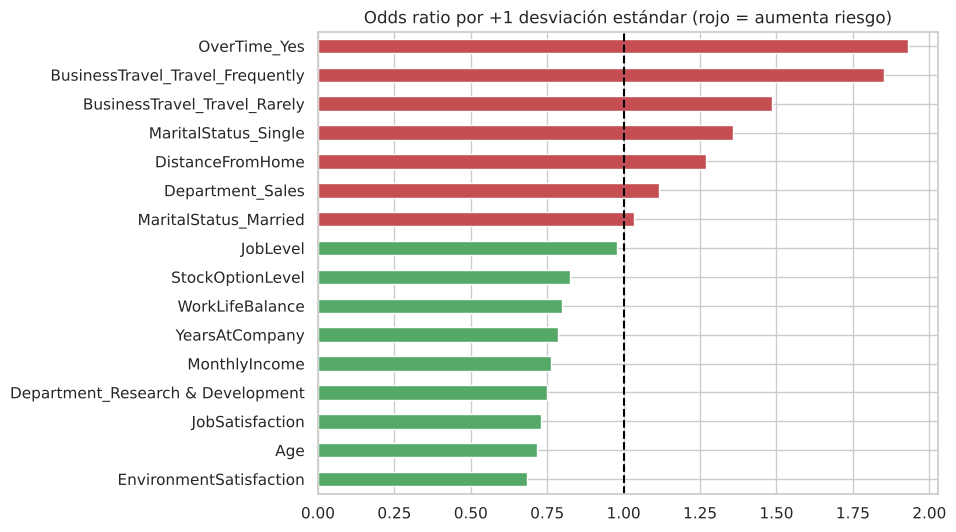

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report
X = pd.get_dummies(df[['OverTime','MonthlyIncome','JobSatisfaction','EnvironmentSatisfaction','WorkLifeBalance',
                        'YearsAtCompany','Age','DistanceFromHome','StockOptionLevel','MaritalStatus','BusinessTravel','Department','JobLevel']],
                   drop_first=True).astype(float)
y = df.Rotacion
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
sc = StandardScaler().fit(Xtr)
m = LogisticRegression(max_iter=2000, class_weight='balanced').fit(sc.transform(Xtr), ytr)
pred = m.predict_proba(sc.transform(Xte))[:,1]
print(f'AUC en prueba: {roc_auc_score(yte, pred):.3f}')
print(classification_report(yte, (pred>0.5).astype(int), target_names=['Activo','Se fue']))
orr = pd.Series(np.exp(m.coef_[0]), index=X.columns).sort_values()
orr.plot.barh(figsize=(8,6), color=['#55A868' if v<1 else '#C44E52' for v in orr]); plt.axvline(1, c='k', ls='--')
plt.title('Odds ratio por +1 desviación estándar (rojo = aumenta riesgo)'); plt.show()

# Fase 4. KPIs
Las fórmulas DAX equivalentes están en `docs/dashboard_powerbi.md`.

In [10]:
act, fue = df[df.Rotacion==0], df[df.Rotacion==1]
kpi = {
 'KPI1 Tasa de rotación (%)': df.Rotacion.mean()*100,
 'KPI2 Rotación con horas extra (%)': df[df.OverTime=='Yes'].Rotacion.mean()*100,
 'KPI2b Rotación sin horas extra (%)': df[df.OverTime=='No'].Rotacion.mean()*100,
 'KPI3 Brecha salarial activos vs salidos (%)': (act.MonthlyIncome.median()/fue.MonthlyIncome.median()-1)*100,
 'KPI4 % empleados con satisfacción baja (1)': (df.JobSatisfaction==1).mean()*100,
 'KPI5 Rotación temprana (≤2 años) (%)': df[df.YearsAtCompany<=2].Rotacion.mean()*100,
 'KPI6 Índice de satisfacción promedio (1-4)': df.IndiceSatisfaccion.mean(),
 'KPI7 Antigüedad media (años)': df.YearsAtCompany.mean(),
}
pd.Series(kpi).round(2).to_frame('Valor')

,Valor
KPI1 Tasa de rotación (%),16.12
KPI2 Rotación con horas extra (%),30.53
KPI2b Rotación sin horas extra (%),10.44
KPI3 Brecha salarial activos vs salidos (%),62.52
KPI4 % empleados con satisfacción baja (1),19.66
KPI5 Rotación temprana (≤2 años) (%),29.82
KPI6 Índice de satisfacción promedio (1-4),2.73
KPI7 Antigüedad media (años),7.01


| KPI | Justificación de negocio | Hipótesis | Lectura |
|---|---|---|---|
| **Tasa de rotación** | Indicador principal de retención; la referencia sana en la industria está entre 10 % y 12 % | Todas | ~16 %: por encima de la referencia |
| **Rotación con vs sin horas extra** | Mide el efecto de la carga laboral | H1 | ~30 % vs ~10 %: casi 3 veces más |
| **Brecha salarial activos/salidos** | Detecta si la compensación es poco competitiva | H2 | Los activos ganan ~60 % más (mediana) |
| **% satisfacción baja** | Alerta temprana de clima laboral | H3 | ~20 % de la plantilla está en nivel 1 |
| **Rotación temprana (≤2 años)** | Mide qué tan bien funcionan la selección y el onboarding | H5 | ~30 %: la mayoría de las salidas ocurre al inicio |
| **Índice de satisfacción** | Resume cuatro encuestas de clima | H3 | Promedio ~2,7 de 4 |

# Fase 6. Análisis, validación y storytelling
**Interpretación (comprobar con los valores de las celdas anteriores):**
1. **Horas extra (H1):** p ≈ 1e-21, se rechaza H0. Es el factor con mayor efecto (V ≈ 0,25) y también el odds ratio más alto en el modelo logístico.
2. **Ingreso (H2):** p < 0,001, se rechaza H0. Quienes se van tienen una mediana cercana a USD 3.200 frente a ~5.200 de los activos. La rotación se concentra en el cuartil de ingreso más bajo.
3. **Satisfacción (H3):** p < 0,001, se rechaza H0. Con satisfacción baja la rotación es ~23 %; con satisfacción muy alta, ~11 %. El efecto es pequeño (V ≈ 0,1), pero significativo.
4. **Departamento (H4):** p ≈ 0,005, se rechaza H0. Ventas (~21 %) y RR.HH. (~19 %) superan a I+D (~14 %). Por cargo, *Sales Representative* (~40 %) es el más crítico.
5. **Antigüedad (H5):** p < 0,001, se rechaza H0. Las salidas se concentran en los primeros 2 años.

**Narrativa:** *"El empleado con mayor riesgo de irse es joven, soltero, con poca antigüedad, en el nivel salarial más bajo, del área comercial y haciendo horas extra."*

**Decisiones propuestas**
- Limitar y compensar las horas extra; monitorear el KPI2 cada mes.
- Revisar la banda salarial de los niveles 1 y 2, en especial de Sales Representative y Lab Technician.
- Fortalecer el onboarding y el acompañamiento en los primeros 24 meses (mentoría, check-ins a los 3, 6 y 12 meses).
- Encuesta de clima trimestral con alerta cuando el índice de satisfacción sea ≤ 2.
- Usar el modelo logístico como un *score* de riesgo para conversaciones preventivas de retención.

**Limitaciones**
- El dataset es **ficticio** (creado por científicos de datos de IBM), así que los hallazgos ilustran el método y no describen una empresa real.
- Es una foto en un solo momento (transversal): muestra asociación, no causalidad.
- Las clases están desbalanceadas (16 % vs 84 %); por eso se usan `class_weight` y AUC.
- Las encuestas de satisfacción son autorreportadas y en escala ordinal corta.
- No distingue entre salida voluntaria y despido, ni incluye variables externas como el mercado laboral.